In [1]:
import keras
import ml_edu.experiment
import ml_edu.results
import numpy as np
import pandas as pd
import plotly.express as px

I0000 00:00:1793296465.762024  320308 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Load and explore the dataset

In [2]:
chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")

In [3]:
training_df = chicago_taxi_dataset.loc[:, ('TRIP_MILES', 'TRIP_SECONDS', 'FARE', 'COMPANY', 'PAYMENT_TYPE', 'TIP_RATE')]
if not isinstance(training_df, pd.DataFrame):
    raise TypeError("Something's wrong with the dataset")

print(f"Total number of rows: {len(training_df.index)}")
training_df.head(200)

Total number of rows: 31694


,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
0,2.57,2341,31.99,Flash Cab,Mobile,6.3
1,1.18,1074,9.75,Flash Cab,Credit Card,27.9
2,1.29,1173,10.25,Sun Taxi,Cash,0.0
3,3.70,3360,23.75,Choice Taxi Association,Cash,0.0
4,1.15,1044,10.00,Flash Cab,Cash,0.0
...,...,...,...,...,...,...
195,1.13,821,9.00,Blue Ribbon Taxi Association,Mobile,22.9
196,0.57,414,6.00,Flash Cab,Cash,0.0
197,1.22,886,9.00,City Service,Cash,0.0
198,1.68,1219,9.00,Sun Taxi,Mobile,23.0


In [4]:
training_df.describe(include='all')

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000
unique,NaN,NaN,NaN,31,7,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN
freq,NaN,NaN,NaN,7887,14142,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000


In [5]:
training_df.corr(numeric_only=True)

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294
FARE,0.975344,0.830292,1.000000,-0.070979
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000


In [6]:
px.scatter_matrix(training_df, dimensions=["FARE", "TRIP_MILES", "TRIP_SECONDS"])

# Define helper functions to create and train a model

In [7]:
def create_model(
        settings: ml_edu.experiment.ExperimentSettings,
        metrics: list[keras.metrics.Metric],
) -> keras.Model:
    """Create and compile a simple linear regression model"""
    inputs = {name: keras.Input(shape=(1,), name=name) for name in settings.input_features}
    concatenated_inputs = keras.layers.Concatenate()(list(inputs.values()))
    outputs = keras.layers.Dense(units=1)(concatenated_inputs)
    model = keras.Model(inputs=inputs, outputs=outputs)

    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=settings.learning_rate),
                  loss="mean_squared_error",
                  metrics=metrics)

    return model

def train_model(
        experiment_name: str,
        model: keras.Model,
        dataset: pd.DataFrame,
        label_name: str,
        settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
    """Train the model by feeding it data."""
    features = {name: dataset[name].values for name in settings.input_features}
    label = dataset[label_name].values
    history = model.fit(x=features,
                        y=label,
                        batch_size=settings.batch_size,
                        epochs=settings.number_epochs)

    return ml_edu.experiment.Experiment(
        name=experiment_name,
        settings=settings,
        model=model,
        epochs=history.epoch,
        metrics_history=pd.DataFrame(history.history),
    )

# Model with one feature

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 431.0773 - rmse: 20.7624
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 188.4151 - rmse: 13.7264
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 53.8944 - rmse: 7.3413
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 17.9510 - rmse: 4.2369
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 16.3308 - rmse: 4.0411
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 15.4022 - rmse: 3.9246
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.7808 - rmse: 3.8446
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.3932 - rmse: 3.7938
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.1999 - rmse: 3.7683
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.1049 - rmse: 3.7557
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.0634 - rmse: 3.7501
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 14.0454 - rmse: 3.74

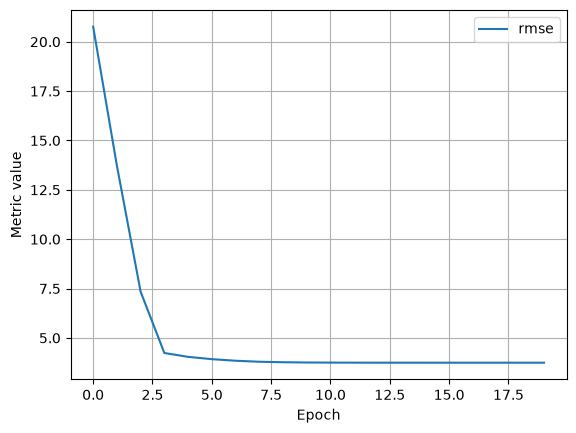

In [9]:
settings_1 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES'],
)

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_1 = create_model(settings_1, metrics)

experiment_1 = train_model('one_feature', model_1, training_df, 'FARE', settings_1)

ml_edu.results.plot_experiment_metrics(experiment_1, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_1, training_df, 'FARE')

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 136.5858 - rmse: 11.6870 
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 932us/step - loss: 30.0025 - rmse: 5.4775
Epoch 3/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 905us/step - loss: 20.0050 - rmse: 4.4727
Epoch 4/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 891us/step - loss: 15.8070 - rmse: 3.9758
Epoch 5/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 903us/step - loss: 14.1894 - rmse: 3.7669
Epoch 6/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 969us/step - loss: 13.3493 - rmse: 3.6537
Epoch 7/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 920us/step - loss: 12.8010 - rmse: 3.5778
Epoch 8/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 946us/step - loss: 12.4647 - rmse: 3.5305
Epoch 9/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 885us/step - loss: 12.2768 - rmse: 3.5038
Epoch 10/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 908us/step - loss: 12.1716 - rmse: 3.4888
Epoch 11/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 944us/step - loss: 12.1312 - rmse: 3.4830
Epoch 12/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 1s 909us/step - loss:

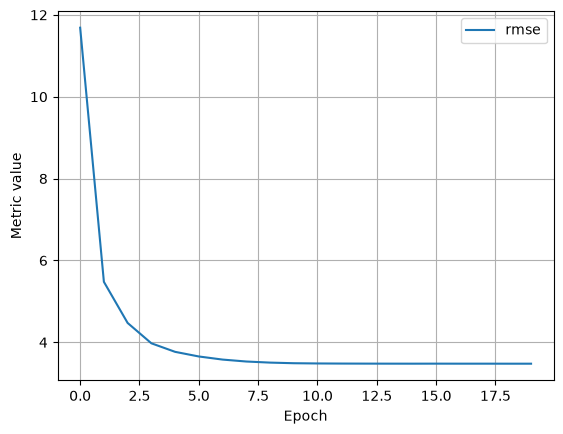

In [16]:
settings_2 = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=20,
    batch_size=50,
    input_features=['TRIP_MILES', 'TRIP_MINUTES'],
)

training_df['TRIP_MINUTES'] = training_df['TRIP_SECONDS'] / 60

metrics = [keras.metrics.RootMeanSquaredError(name='rmse')]

model_2 = create_model(settings_2, metrics)

experiment_2 = train_model('two_features', model_2, training_df, 'FARE', settings_2)

ml_edu.results.plot_experiment_metrics(experiment_2, ['rmse'])
ml_edu.results.plot_model_predictions(experiment_2, training_df, 'FARE')

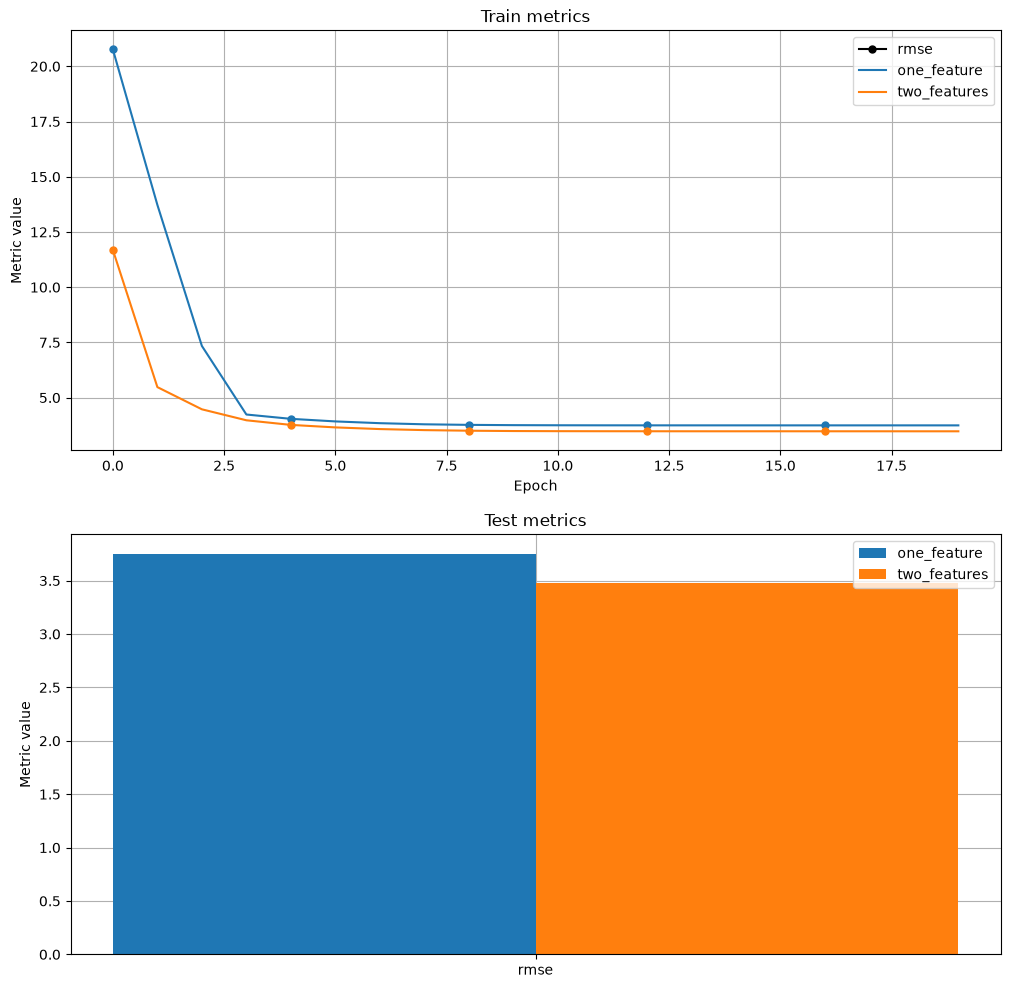

In [17]:
ml_edu.results.compare_experiment([experiment_1, experiment_2], ['rmse'], training_df, training_df['FARE'].values)

# Make predictions

In [23]:
def format_currency(x):
    return f"${x:.2f}"

def build_batch(df, batch_size):
    batch = df.sample(n=batch_size).copy()
    batch.set_index(np.arange(batch_size), inplace=True)
    return batch

def predict_fare(model, df, features, label, batch_size=50):
    batch = build_batch(df, batch_size)
    predicted_values = model.predict_on_batch(x={name: batch[name].values for name in features})

    data = {
        "PREDICTED_FARE": [],
        "OBSERVED_FARE": [],
        "L1_LOSS": [],
        features[0]: [],
        features[1]: [],
    }
    for i in range(batch_size):
        predicted = predicted_values[i][0]
        observed = batch.at[i, label]
        data["PREDICTED_FARE"].append(format_currency(predicted))
        data["OBSERVED_FARE"].append(format_currency(observed))
        data["L1_LOSS"].append(format_currency(abs(observed - predicted)))
        data[features[0]].append(batch.at[i, features[0]])
        data[features[1]].append(f"{batch.at[i, features[1]]:.2f}")

    output_df = pd.DataFrame(data)
    return output_df

def show_predictions(output):
    header = "-" * 80
    banner = header + "\n" + "|" + "PREDICTIONS".center(78) + "|" + "\n" + header
    print(banner)
    print(output)

In [24]:
output = predict_fare(experiment_2.model, training_df, experiment_2.settings.input_features, 'FARE')
show_predictions(output)

--------------------------------------------------------------------------------
|                                 PREDICTIONS                                  |
--------------------------------------------------------------------------------
   PREDICTED_FARE OBSERVED_FARE L1_LOSS  TRIP_MILES TRIP_MINUTES
0           $8.96         $8.25   $0.71        1.84         9.47
1           $8.18         $7.75   $0.43        1.54         8.33
2          $28.10        $27.25   $0.85        9.70        31.00
3          $30.99        $31.75   $0.76       10.98        33.00
4          $21.47        $21.50   $0.03        8.10         8.13
5           $7.66         $7.75   $0.09        1.23         9.03
6          $44.36        $44.00   $0.36       18.00        27.00
7           $7.04        $11.00   $3.96        1.11         6.52
8          $23.10        $22.75   $0.35        8.40        15.00
9          $44.14        $44.25   $0.11       17.84        27.75
10          $5.32         $9.00   $3.68   

/tmp/ipykernel_320308/2101508988.py:6: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  batch.set_index(np.arange(batch_size), inplace=True)
